In [1]:
import os
import pandas as pd

# Locate the CSV file whether running from root or notebooks directory
path = (
    'data/raw/Bengaluru Monthly Rainfall Data (1900-2025).csv'
    if os.path.exists('data/raw/Bengaluru Monthly Rainfall Data (1900-2025).csv')
    else '../data/raw/Bengaluru Monthly Rainfall Data (1900-2025).csv'
)

rain = pd.read_csv(path)
rain.head()

,Year,Jan,Feb,Mar,Apr,May,June,July,Aug,Sept,Oct,Nov,Dec,Total,El NiNo (Y/N),La Nina (Y/N)
0,1901,0.0,78.9,0.0,24.3,146.0,47.7,71.6,71.6,318.5,120.3,37.3,23.1,939.3,Y,N
1,1902,0.7,0.0,17.0,58.1,197.8,62.2,32.0,79.5,213.6,219.9,11.1,25.4,917.3,N,N
2,1903,0.0,0.0,0.0,1.5,63.7,109.2,27.9,189.7,475.2,171.1,233.6,29.4,1301.3,Y,N
3,1904,0.5,0.0,0.0,14.4,241.5,49.5,149.3,53.8,126.4,157.2,0.0,1.7,794.3,N,Y
4,1905,1.7,0.0,56.6,32.7,90.6,60.7,58.9,266.4,62.4,227.8,29.2,3.0,890.0,N,N


In [2]:
rain.shape

(127, 16)

In [3]:
rain.columns

Index(['Year', 'Jan', 'Feb', 'Mar', 'Apr', 'May', 'June', 'July', 'Aug',
       'Sept', 'Oct', 'Nov', 'Dec', 'Total', 'El NiNo (Y/N)', 'La Nina (Y/N)'],
      dtype='str')

In [4]:
rain.info()

<class 'pandas.DataFrame'>
RangeIndex: 127 entries, 0 to 126
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Year           127 non-null    str    
 1   Jan            127 non-null    float64
 2   Feb            127 non-null    float64
 3   Mar            127 non-null    float64
 4   Apr            127 non-null    float64
 5   May            127 non-null    float64
 6   June           127 non-null    float64
 7   July           127 non-null    float64
 8   Aug            127 non-null    float64
 9   Sept           127 non-null    float64
 10  Oct            127 non-null    float64
 11  Nov            127 non-null    float64
 12  Dec            126 non-null    float64
 13  Total          127 non-null    float64
 14  El NiNo (Y/N)  125 non-null    str    
 15  La Nina (Y/N)  125 non-null    str    
dtypes: float64(13), str(3)
memory usage: 16.0 KB


In [5]:
rain.isnull().sum()

Year             0
Jan              0
Feb              0
Mar              0
Apr              0
May              0
June             0
July             0
Aug              0
Sept             0
Oct              0
Nov              0
Dec              1
Total            0
El NiNo (Y/N)    2
La Nina (Y/N)    2
dtype: int64

In [6]:
rain.describe()

,Jan,Feb,Mar,Apr,May,June,July,Aug,Sept,Oct,Nov,Dec,Total
count,127.000000,127.000000,127.000000,127.000000,127.000000,127.000000,127.000000,127.000000,127.000000,127.000000,127.000000,126.000000,127.000000
mean,4.324409,7.351181,11.599213,50.126772,119.982677,84.942520,110.962992,140.323622,187.857480,165.600000,61.352756,17.403175,962.062205
std,10.812623,17.125952,20.871647,51.703063,60.069905,50.282626,61.725898,84.777969,105.362578,101.720791,63.530565,23.944793,229.771497
min,0.000000,0.000000,0.000000,0.000000,1.300000,4.500000,18.500000,12.600000,8.300000,3.200000,0.000000,0.000000,543.800000
25%,0.000000,0.000000,0.000000,13.450000,76.050000,55.850000,67.600000,75.250000,106.500000,91.200000,19.850000,1.000000,796.950000
50%,0.000000,0.000000,1.500000,32.200000,112.100000,75.700000,100.900000,121.100000,176.200000,159.700000,37.300000,7.450000,950.700000
75%,4.200000,4.550000,15.200000,75.000000,154.200000,106.750000,141.200000,177.500000,242.650000,205.550000,83.350000,21.775000,1083.600000
max,101.800000,89.900000,115.400000,323.800000,315.000000,255.500000,350.200000,387.100000,516.600000,522.200000,296.400000,119.200000,1957.700000


# Data Card: Bengaluru Rainfall Dataset

## 1. Dataset Description
This dataset contains historical monthly rainfall records for Bengaluru, along with annual rainfall totals and El Niño/La Niña climate indicators.

## 2. What Does One Row Represent?
Each historical row represents the rainfall recorded for Bengaluru during one calendar year. The monthly columns contain rainfall measurements for January to December, and the Total column represents the annual rainfall.

The dataset also contains Long Period Average (LPA) records, which represent average rainfall over specified reference periods rather than individual years.

## 3. Time Period Covered
The dataset includes historical rainfall observations beginning from 1950, along with LPA reference periods such as 1981–2010 and 1991–2020.

## 4. Important Columns

| Column | Description |
|---|---|
| Year | Calendar year or LPA reference period |
| Jan–Dec | Monthly rainfall measurements |
| Total | Annual rainfall total |
| El Niño (Y/N) | El Niño indicator |
| La Niña (Y/N) | La Niña indicator |

## 5. Relevance to HydroGrid
Rainfall is an important meteorological input for understanding water availability, seasonal variations and groundwater recharge patterns. This dataset can help investigate historical rainfall trends for HydroGrid's water demand and supply analysis.

## 6. Data Quality Observations
Initial exploration identified missing values in December rainfall for 1950 and in the El Niño/La Niña columns for the two LPA records. These records require further investigation before preprocessing.

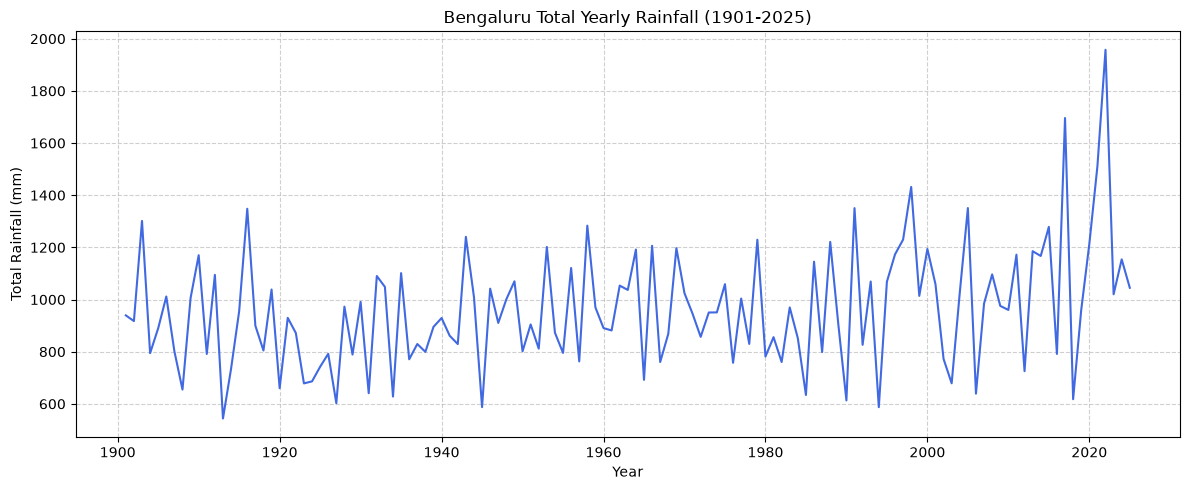

In [7]:
import matplotlib.pyplot as plt

# Filter out summary rows like LPA to keep only actual years
yearly_rain = rain[rain['Year'].astype(str).str.isnumeric()].copy()
yearly_rain['Year'] = yearly_rain['Year'].astype(int)

# Plot total yearly rainfall over time
plt.figure(figsize=(12, 5))
plt.plot(yearly_rain['Year'], yearly_rain['Total'], color='royalblue', linewidth=1.5)
plt.title('Bengaluru Total Yearly Rainfall (1901-2025)')
plt.xlabel('Year')
plt.ylabel('Total Rainfall (mm)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [8]:
path2 = (
    'data/raw/Water Tanker Data (2024).csv'
    if os.path.exists('data/raw/Water Tanker Data (2024).csv')
    else '../data/raw/Water Tanker Data (2024).csv'
)

tanker = pd.read_csv(path2)
tanker.head()

,Sources of water supply for your community,"If you don't get water from tankers, what do you rely on for water needs?",How much do you pay for a single tanker of water?,What is the capacity of the tanker in litres?,Your area Pincode,Type of Community,Frequency of purchase of private water tanker,How many private tankers do you get per month on average?,Number of units in the community,Do you have water rationing?,Do you use treated STP water for flushing/gardening?,What is your community's monthly expense on water?,Number of dry days in the past year?,Have you been ordering private water tankers more often in the last three months?,Has the supply of water from BWSSB changed during the last one year (both in terms of frequency as well as quantity)?,How much were you paying for the same tanker of water a year back (Feb 2023)?,How often does your water tanker vendor raise rates?
0,"BWSSB/Municipal/Cauvery Water, Borewell",NaN,1500,6000,560005,Apartments,Only for Emergency,1,120,No,NaN,75000,20,Not ordered private tankers in last 3 months,No change,NaN,Annually
1,"Private water tankers, Borewell",NaN,1000,5000,560016,Apartments,Daily,90,30,No,NaN,70000,0,More often,NA - No BWSSB supply,350.0,Every quarter
2,"Private water tankers, BWSSB/Municipal/Cauvery...",NaN,1200,13000,560022,Apartments,Weekly,8,120,No,NaN,35000,0,More often,No change,1200.0,Annually
3,"Private water tankers, BWSSB/Municipal/Cauvery...",NaN,500,6000,560023,Apartments,Daily,350,356,No,NaN,175000,Nil,More often,Reduced,400.0,Annually
4,"Private water tankers, BWSSB/Municipal/Cauvery...",NaN,800,6000,560023,Apartments,Daily,600,703,No,NaN,800000,2,More often,No change,550.0,Every 6 months


In [9]:
tanker.info()

<class 'pandas.DataFrame'>
RangeIndex: 160 entries, 0 to 159
Data columns (total 17 columns):
 #   Column                                                                                                                  Non-Null Count  Dtype  
---  ------                                                                                                                  --------------  -----  
 0   Sources of water supply for your community                                                                              160 non-null    str    
 1   If you don't get water from tankers, what do you rely on for water needs?                                               0 non-null      float64
 2   How much do you pay for a single tanker of water?                                                                       160 non-null    int64  
 3   What is the capacity of the tanker in litres?                                                                           160 non-null    int64  
 4   Your ar

In [10]:
tanker.isnull().sum()

Sources of water supply for your community                                                                                  0
If you don't get water from tankers, what do you rely on for water needs?                                                 160
How much do you pay for a single tanker of water?                                                                           0
What is the capacity of the tanker in litres?                                                                               0
Your area Pincode                                                                                                           0
Type of Community                                                                                                           0
Frequency of purchase of private water tanker                                                                               0
How many private tankers do you get per month on average?                                                             

# Data Card: Bengaluru Water Tanker Survey Dataset (2024)

## 1. Dataset Description
This dataset contains survey responses about private water tanker usage, water supply sources, tanker pricing, water consumption expenses and water availability across different communities in Bengaluru.

It provides information about how residential communities depend on private water tankers and other water sources.

## 2. Dataset Dimensions
- **Total Records (Rows):** 160
- **Total Features (Columns):** 17
- **Data Types:** 10 string columns, 4 integer columns and 3 float columns.

## 3. What Does One Row Represent?
Each row represents a survey response from a community regarding its water supply arrangements, private tanker usage, water expenditure and water availability.

## 4. Important Columns and Their Descriptions

| Column | Description |
|---|---|
| Sources of water supply for your community | Water sources used by the community, such as BWSSB, Cauvery water, borewells and private tankers |
| If you don't get water from tankers, what do you rely on for water needs? | Alternative water sources |
| How much do you pay for a single tanker of water? | Current price paid for one tanker |
| What is the capacity of the tanker in litres? | Tanker capacity in litres |
| Your area Pincode | Geographic identifier of the community |
| Type of Community | Residential community category, such as apartments |
| Frequency of purchase of private water tanker | How frequently the community purchases private tankers |
| How many private tankers do you get per month on average? | Average monthly tanker purchases |
| Number of units in the community | Number of residential units in the community |
| Do you have water rationing? | Indicates whether the community experiences water rationing |
| Do you use treated STP water for flushing/gardening? | Indicates reuse of treated sewage treatment plant water |
| What is your community's monthly expense on water? | Monthly expenditure on water |
| Number of dry days in the past year? | Reported number of days without adequate water availability |
| Have you been ordering private water tankers more often in the last three months? | Change in recent tanker purchasing frequency |
| Has the supply of water from BWSSB changed during the last one year? | Reported change in municipal water supply |
| How much were you paying for the same tanker of water a year back (Feb 2023)? | Historical tanker price for comparison |
| How often does your water tanker vendor raise rates? | Frequency of tanker price increases |

## 5. Missing Value Analysis

Initial exploration identified missing values in the following columns:

| Column | Missing Values |
|---|---:|
| Alternative water sources | 160 |
| Treated STP water usage | 160 |
| Monthly water expenditure | 8 |
| Number of dry days | 34 |
| Previous year's tanker price | 21 |
| Frequency of vendor rate increases | 10 |

The first two columns contain no available responses and require investigation to determine whether they are unused survey questions or data collection issues.

Other missing values need to be investigated before deciding on an appropriate treatment.

## 6. Data Quality Observations
- The dataset contains 160 community-level survey responses.
- Two columns are completely empty.
- Some numerical-looking fields are stored as strings, including the number of community units and dry days.
- The dataset includes both current and historical tanker pricing information.
- Categorical responses may require standardization before analysis.
- Missing values should not automatically be replaced with zero.

## 7. Relevance to HydroGrid
This dataset can help investigate Bengaluru's dependence on private water tankers, variations in tanker pricing, water availability and differences in water requirements across residential communities.

Potential applications include:
- Understanding dependence on private water tankers.
- Analysing geographical differences in tanker usage using pincodes.
- Studying tanker price variations.
- Identifying communities experiencing water shortages.
- Investigating the relationship between water rationing and tanker demand.

## 8. Limitations
- The dataset contains only 160 survey responses.
- Survey responses may not represent all Bengaluru communities.
- Some columns have substantial missing information.
- The dataset represents reported community-level information rather than continuous, sensor-based water consumption measurements.
- The survey alone cannot establish actual city-wide water demand or groundwater extraction.

## 9. Preprocessing Requirements
Before using this dataset for HydroGrid:
1. Investigate completely empty columns.
2. Examine and handle missing values.
3. Convert numerical fields stored as strings into appropriate numerical types where valid.
4. Standardize categorical responses.
5. Validate tanker capacity, price and monthly purchase counts.
6. Examine duplicate responses and inconsistent records.
7. Preserve the original raw dataset and perform cleaning on a separate processed copy.

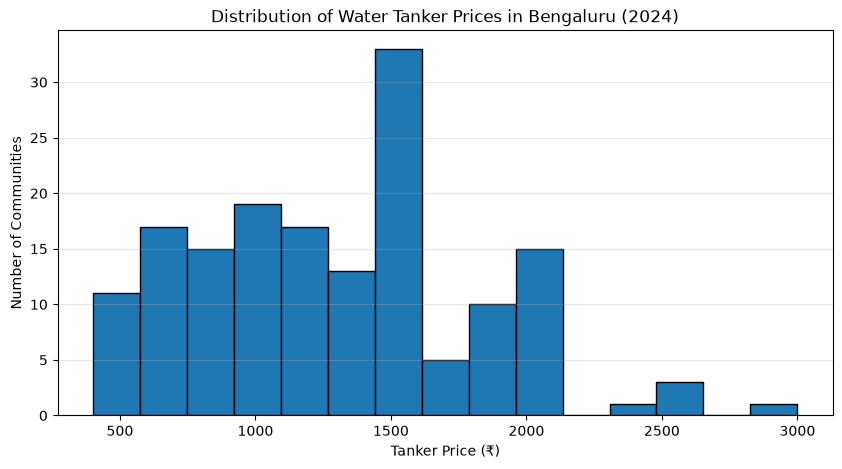

In [11]:
import matplotlib.pyplot as plt

# Plot histogram of tanker prices
plt.figure(figsize=(10, 5))

plt.hist(
    tanker['How much do you pay for a single tanker of water?'],
    bins=15,
    edgecolor='black'
)

plt.xlabel('Tanker Price (₹)')
plt.ylabel('Number of Communities')
plt.title('Distribution of Water Tanker Prices in Bengaluru (2024)')

plt.grid(axis='y', alpha=0.3)
plt.show()

In [12]:
# Load 2019 Tanker Data
path_2019 = (
    'data/raw/Water Tanker Data (2019).csv'
    if os.path.exists('data/raw/Water Tanker Data (2019).csv')
    else '../data/raw/Water Tanker Data (2019).csv'
)
tanker_2019 = pd.read_csv(path_2019)
tanker_2019.head()

,Type,No of units,Apartment Name / House Address,Monthly expense on water,Do you have water rationing?,How many dry days recently?,Source of water (Select multiple if required),How often do you buy water,No of tankers,Tanker capacity (in litres),Average tanker price,Do you use treated STP water for flushing/gardening?
0,Apartment,12,Electronics City Phase 1,19000,NaN,NaN,Tanker Water,1,1,6500,650,No
1,Independent House,NaN,"3694, 9th cross, 13th Main, Doopanahalli, Indi...",300,NaN,NaN,BWSSB,NaN,NaN,NaN,NaN,NaN
2,Apartment,96,Kristal Campus II\r\n79/6 \r\nBELLANDUR,75000,Not yet,One,Borewell\nTanker Water,Daily,2 to 3 daily,12000 litres,1400,No
3,Independent House,NaN,Ferns Paradise,About 500/-,Yes.,Yes.,BWSSB\nBorewell\nTanker Water,3 weeks,1,4000 litres,500/-,NaN
4,Apartment,32,"Smaart Forte, 45 Owners Court\r\nkasavanahalli...",30000,No,8,Borewell\nTanker Water,1,2,6000,650,No


In [13]:
tanker_2019.info()

<class 'pandas.DataFrame'>
RangeIndex: 342 entries, 0 to 341
Data columns (total 12 columns):
 #   Column                                                Non-Null Count  Dtype
---  ------                                                --------------  -----
 0   Type                                                  342 non-null    str  
 1   No of units                                           211 non-null    str  
 2   Apartment Name / House Address                        341 non-null    str  
 3   Monthly expense on water                              342 non-null    str  
 4   Do you have water rationing?                          269 non-null    str  
 5   How many dry days  recently?                          221 non-null    str  
 6   Source of water (Select multiple if required)         342 non-null    str  
 7   How often do you buy water                            222 non-null    str  
 8   No of tankers                                         222 non-null    str  
 9   Tanker cap

In [14]:
tanker_2019.isnull().sum()

Type                                                      0
No of units                                             131
Apartment Name / House Address                            1
Monthly expense on water                                  0
Do you have water rationing?                             73
How many dry days  recently?                            121
Source of water (Select multiple if required)             0
How often do you buy water                              120
No of tankers                                           120
Tanker capacity (in litres)                             120
Average tanker price                                    121
Do you use treated STP water for flushing/gardening?    131
dtype: int64

# Data Card: Bengaluru Water Tanker Survey Dataset (2019)

## 1. Dataset Description
This dataset captures community survey responses collected in 2019 regarding residential water sources, water rationing, tanker prices and monthly water expenses across Bengaluru.

## 2. Dataset Dimensions
- **Total Records (Rows):** 342
- **Total Features (Columns):** 12
- **Key Columns:**
  - **Location/Address:** `Apartment Name / House Address` (No administrative ward column)
  - **Price:** `Average tanker price`
  - **Volume:** `Tanker capacity (in litres)`
  - **Units:** `No of units`
  - **Source:** `Source of water (Select multiple if required)`

## 3. Missing Value Analysis
- `Average tanker price`: 121 missing values
- `Tanker capacity (in litres)`: 120 missing values
- `No of units`: 131 missing values
- `Do you have water rationing?`: 73 missing values

## 4. Relevance & Quality Observations
- Larger sample size than 2024 (342 respondents).
- Tanker prices often include suffixes like `/-` or text requiring regex cleaning before numerical analysis.
- Covers multiple housing types: apartments and independent houses.


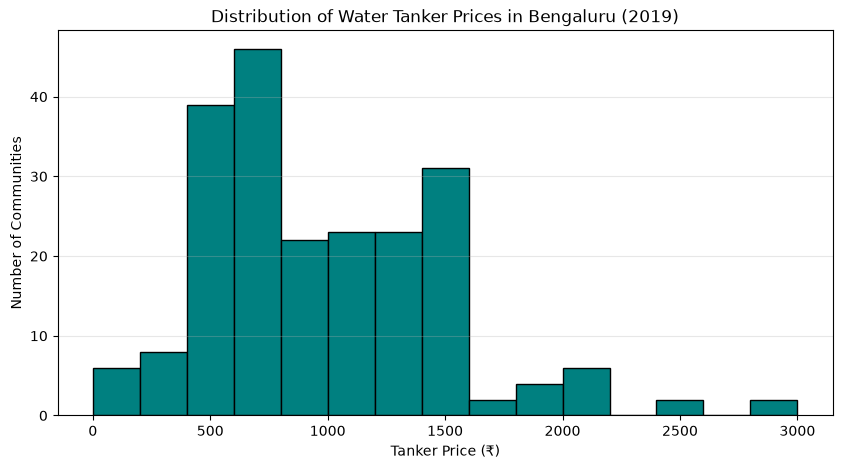

In [15]:
# Clean and plot histogram of 2019 tanker prices
prices_2019 = (
    tanker_2019['Average tanker price']
    .dropna()
    .astype(str)
    .str.extract(r'(\d+)', expand=False)
    .astype(float)
)

# Filter out extreme outliers for clean visualization (under 5000)
prices_2019_filtered = prices_2019[prices_2019 <= 5000]

plt.figure(figsize=(10, 5))
plt.hist(prices_2019_filtered, bins=15, edgecolor='black', color='teal')
plt.xlabel('Tanker Price (₹)')
plt.ylabel('Number of Communities')
plt.title('Distribution of Water Tanker Prices in Bengaluru (2019)')
plt.grid(axis='y', alpha=0.3)
plt.show()

In [16]:
import csv

# Load 2015 Tanker Data (joining unescaped commas in multi-choice source column)
path_2015 = (
    'data/raw/Tanker Water Data (2015).csv'
    if os.path.exists('data/raw/Tanker Water Data (2015).csv')
    else '../data/raw/Tanker Water Data (2015).csv'
)

rows_2015 = []
with open(path_2015, 'r', encoding='utf-8', errors='ignore') as f:
    reader = csv.reader(f)
    header_2015 = next(reader)
    for row in reader:
        if len(row) == 9:
            rows_2015.append(row)
        else:
            if 'RT Nagar' in row[0]:
                source = '; '.join(row[2:4])
                freq = ', '.join(row[4:6])
                fixed = [row[0], row[1], source, freq] + row[6:]
            else:
                source = '; '.join(row[2:len(row)-6])
                fixed = [row[0], row[1], source, row[-6], row[-5], row[-4], row[-3], row[-2], row[-1]]
            rows_2015.append(fixed)

tanker_2015 = pd.DataFrame(rows_2015, columns=header_2015)
tanker_2015.head()

,Area where apartment is situated,No of housing units,Source of water,Frequency of purchasing water,No of tankers,Tanker capacity (in litres),Average tanker price,Prorated amount for 6000 litre tanker,Variation in cost with season
0,Hosa road,4,Private tanker water,Weekly,10,4000,350,525,No
1,Koramangala 4th block,128,BWSSB/Municipal/Cauvery water; Groundwater (B...,Weekly,360,6000,600,600,Up to double the rate
2,Ali Asker road,95,BWSSB/Municipal/Cauvery water; Groundwater (B...,Only for emergencies,2,7000,800,686,Rs 100 to 200
3,Singasandra,44,Groundwater (Borewell); Private tanker water,Daily,5,4000,360,540,No
4,Hosur road,296,Groundwater (Borewell); Private tanker water,Daily,7,14000,850,364,10 to 15 percent


In [17]:
tanker_2015.info()

<class 'pandas.DataFrame'>
RangeIndex: 98 entries, 0 to 97
Data columns (total 9 columns):
 #   Column                                 Non-Null Count  Dtype
---  ------                                 --------------  -----
 0   Area where apartment is situated       98 non-null     str  
 1   No of housing units                    98 non-null     str  
 2   Source of water                        98 non-null     str  
 3   Frequency of purchasing water          98 non-null     str  
 4   No of tankers                          98 non-null     str  
 5   Tanker capacity (in litres)            98 non-null     str  
 6   Average tanker price                   98 non-null     str  
 7   Prorated amount for 6000 litre tanker  98 non-null     str  
 8   Variation in cost with season          98 non-null     str  
dtypes: str(9)
memory usage: 7.0 KB


In [18]:
tanker_2015.isnull().sum()

Area where apartment is situated         0
No of housing units                      0
Source of water                          0
Frequency of purchasing water            0
No of tankers                            0
Tanker capacity (in litres)              0
Average tanker price                     0
Prorated amount for 6000 litre tanker    0
Variation in cost with season            0
dtype: int64

# Data Card: Bengaluru Water Tanker Survey Dataset (2015)

## 1. Dataset Description
This dataset contains survey responses gathered from apartment communities across Bengaluru in 2015, recording water sources, purchase frequencies, tanker capacities, and seasonal rate variations.

## 2. Dataset Dimensions
- **Total Records (Rows):** 98
- **Total Features (Columns):** 9
- **Key Columns:**
  - **Location:** `Area where apartment is situated` (No administrative ward column)
  - **Price:** `Average tanker price` and `Prorated amount for 6000 litre tanker`
  - **Volume:** `Tanker capacity (in litres)`
  - **Units:** `No of housing units`
  - **Source:** `Source of water`

## 3. Data Quality & Observations
- Raw CSV contains unquoted commas inside the multiple-choice water source answers, causing extra fields that require parsing logic.
- Missing values appear as `'NA'` or empty strings rather than standard nulls.
- Includes a unique column tracking seasonal price surges: `Variation in cost with season`.


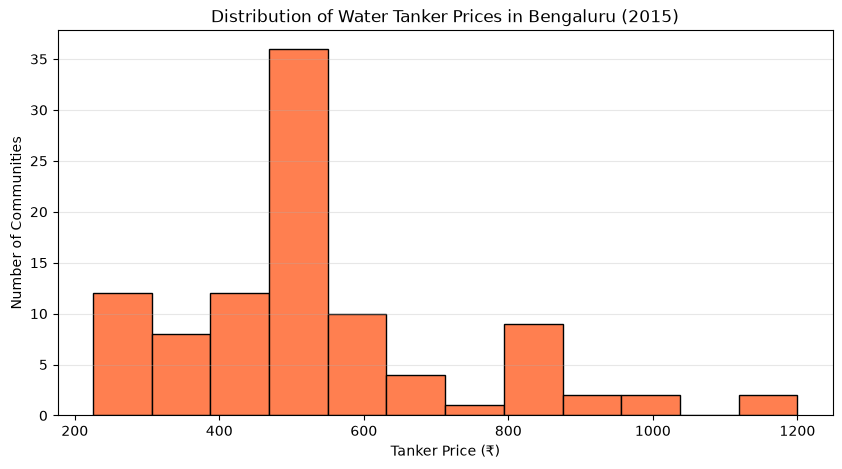

In [19]:
# Clean and plot histogram of 2015 tanker prices
prices_2015 = pd.to_numeric(tanker_2015['Average tanker price'], errors='coerce').dropna()

plt.figure(figsize=(10, 5))
plt.hist(prices_2015, bins=12, edgecolor='black', color='coral')
plt.xlabel('Tanker Price (₹)')
plt.ylabel('Number of Communities')
plt.title('Distribution of Water Tanker Prices in Bengaluru (2015)')
plt.grid(axis='y', alpha=0.3)
plt.show()

# Cross-Year Comparison: Water Tanker Data (2015 vs 2019 vs 2024)

## Are Column Names the Same Across Years?
**No, column names and question formats are completely different across the three years.**

Here is the cross-year column alignment:

| Core Concept | 2015 Column Name | 2019 Column Name | 2024 Column Name |
|---|---|---|---|
| **Location / Ward** | `Area where apartment is situated` | `Apartment Name / House Address` | `Your area Pincode` |
| **Price** | `Average tanker price` | `Average tanker price` | `How much do you pay for a single tanker of water?` |
| **Volume / Capacity** | `Tanker capacity (in litres)` | `Tanker capacity (in litres)` | `What is the capacity of the tanker in litres?` |
| **Community Size** | `No of housing units` | `No of units` | `Number of units in the community` |
| **Purchase Frequency**| `Frequency of purchasing water` | `How often do you buy water` | `Frequency of purchase of private water tanker` |
| **Water Sources** | `Source of water` | `Source of water (Select multiple if required)` | `Sources of water supply for your community` |

### Key Observations:
1. **No Standard Ward Column:** None of the three datasets use official BBMP ward numbers or ward names. 2015 used neighborhood names, 2019 used street/apartment addresses, and 2024 used postal pincodes.
2. **Price Inflation Trend:**
   - **2015:** Typical prices clustered between **₹350 – ₹600** (median ₹500).
   - **2019:** Typical prices clustered between **₹600 – ₹1,200** (median ₹800).
   - **2024:** Typical prices escalated to **₹1,200 – ₹2,000+** during the severe crisis.
3. **Data Schema Harmonization Needed:** To merge these datasets into a unified timeline for HydroGrid, column names and geographic identifiers must be standardized.
